# LeetCode #155: Min Stack

https://leetcode.com/problems/min-stack/

## Comparison of Approaches
| Approach | Time | Space |
|---|---|---|
| Two Stacks ★ | O(1) all ops | O(n) |
| Single Stack with Pairs | O(1) all ops | O(n) |

## Understanding the Methods
### Brute Force
A naive approach would scan all elements to find the minimum on each getMin() call — O(n) per call.

### Optimal: Two Stacks ★
Maintain a main stack for all values and a min-stack that tracks the current minimum at each push. When pushing, also push to minStack if the value is <= current min. When popping, also pop from minStack if the popped value equals minStack top. getMin() is just minStack.top() — O(1).

## Solutions
### C#

In [ ]:
public class MinStack {
    private Stack<int> stack = new();
    private Stack<int> minStack = new();

    public void Push(int val) {
        stack.Push(val);
        if (minStack.Count == 0 || val <= minStack.Peek())
            minStack.Push(val);
    }

    public void Pop() {
        int val = stack.Pop();
        if (val == minStack.Peek())
            minStack.Pop();
    }

    public int Top() => stack.Peek();

    public int GetMin() => minStack.Peek();
}

### Python

In [ ]:
class MinStack:
    def __init__(self):
        self.stack = []
        self.min_stack = []

    def push(self, val: int) -> None:
        self.stack.append(val)
        if not self.min_stack or val <= self.min_stack[-1]:
            self.min_stack.append(val)

    def pop(self) -> None:
        val = self.stack.pop()
        if val == self.min_stack[-1]:
            self.min_stack.pop()

    def top(self) -> int:
        return self.stack[-1]

    def getMin(self) -> int:
        return self.min_stack[-1]

### Go

In [ ]:
package main

import "fmt"

type MinStack struct {
    stack    []int
    minStack []int
}

func Constructor() MinStack { return MinStack{} }

func (s *MinStack) Push(val int) {
    s.stack = append(s.stack, val)
    if len(s.minStack) == 0 || val <= s.minStack[len(s.minStack)-1] {
        s.minStack = append(s.minStack, val)
    }
}

func (s *MinStack) Pop() {
    val := s.stack[len(s.stack)-1]
    s.stack = s.stack[:len(s.stack)-1]
    if val == s.minStack[len(s.minStack)-1] {
        s.minStack = s.minStack[:len(s.minStack)-1]
    }
}

func (s *MinStack) Top() int   { return s.stack[len(s.stack)-1] }
func (s *MinStack) GetMin() int { return s.minStack[len(s.minStack)-1] }

func main() {
    ms := Constructor()
    ms.Push(-2); ms.Push(0); ms.Push(-3)
    fmt.Println(ms.GetMin()) // -3
    ms.Pop()
    fmt.Println(ms.Top())    // 0
    fmt.Println(ms.GetMin()) // -2
}

### Rust

In [ ]:
pub struct MinStack {
    stack: Vec<i32>,
    min_stack: Vec<i32>,
}

impl MinStack {
    pub fn new() -> Self {
        MinStack { stack: vec![], min_stack: vec![] }
    }

    pub fn push(&mut self, val: i32) {
        self.stack.push(val);
        if self.min_stack.is_empty() || val <= *self.min_stack.last().unwrap() {
            self.min_stack.push(val);
        }
    }

    pub fn pop(&mut self) {
        let val = self.stack.pop().unwrap();
        if val == *self.min_stack.last().unwrap() {
            self.min_stack.pop();
        }
    }

    pub fn top(&self) -> i32 { *self.stack.last().unwrap() }
    pub fn get_min(&self) -> i32 { *self.min_stack.last().unwrap() }
}

## Example Scenarios

### 1. Common Case — Classic Sequence
**Input:** `push(-2); push(0); push(-3); getMin(); pop(); top(); getMin()`

The min-stack mirrors the current minimum at each depth. `getMin()` returns `-3`, then after `pop()` the min-stack also pops, so `getMin()` correctly returns `-2`.

### 2. Slightly Complex — Duplicate Minimums
**Input:** `push(2); push(2); push(1); pop(); getMin()`

Pushing with `val <= min` (not `<`) keeps the second `2` on the min-stack. After popping the `1`, the duplicate `2` is still there, so `getMin()` stays `2`.

### 3. Edge Case: Time — Every Operation O(1)
**Input:** `push(5); push(3); push(7); getMin(); push(1); getMin()`

`getMin()` just reads the top of the min-stack — $O(1)$ — no scanning. It reports `3`, then `1` after the new minimum is pushed.

### 4. Edge Case: Space — Strictly Decreasing Pushes
**Input:** `push(5); push(4); push(3); push(2); push(1)`

Each value is a new minimum, so the min-stack grows to the same height as the main stack — the $O(n)$ space worst case.

### 5. Almost-Impossible but Plausible — Emptied Completely
**Input:** `push(1); push(2); pop(); pop()`

Both stacks drain back to empty in lock-step. Per the constraints `top()`/`getMin()` are only called on a non-empty stack, so this leaves a valid empty state.


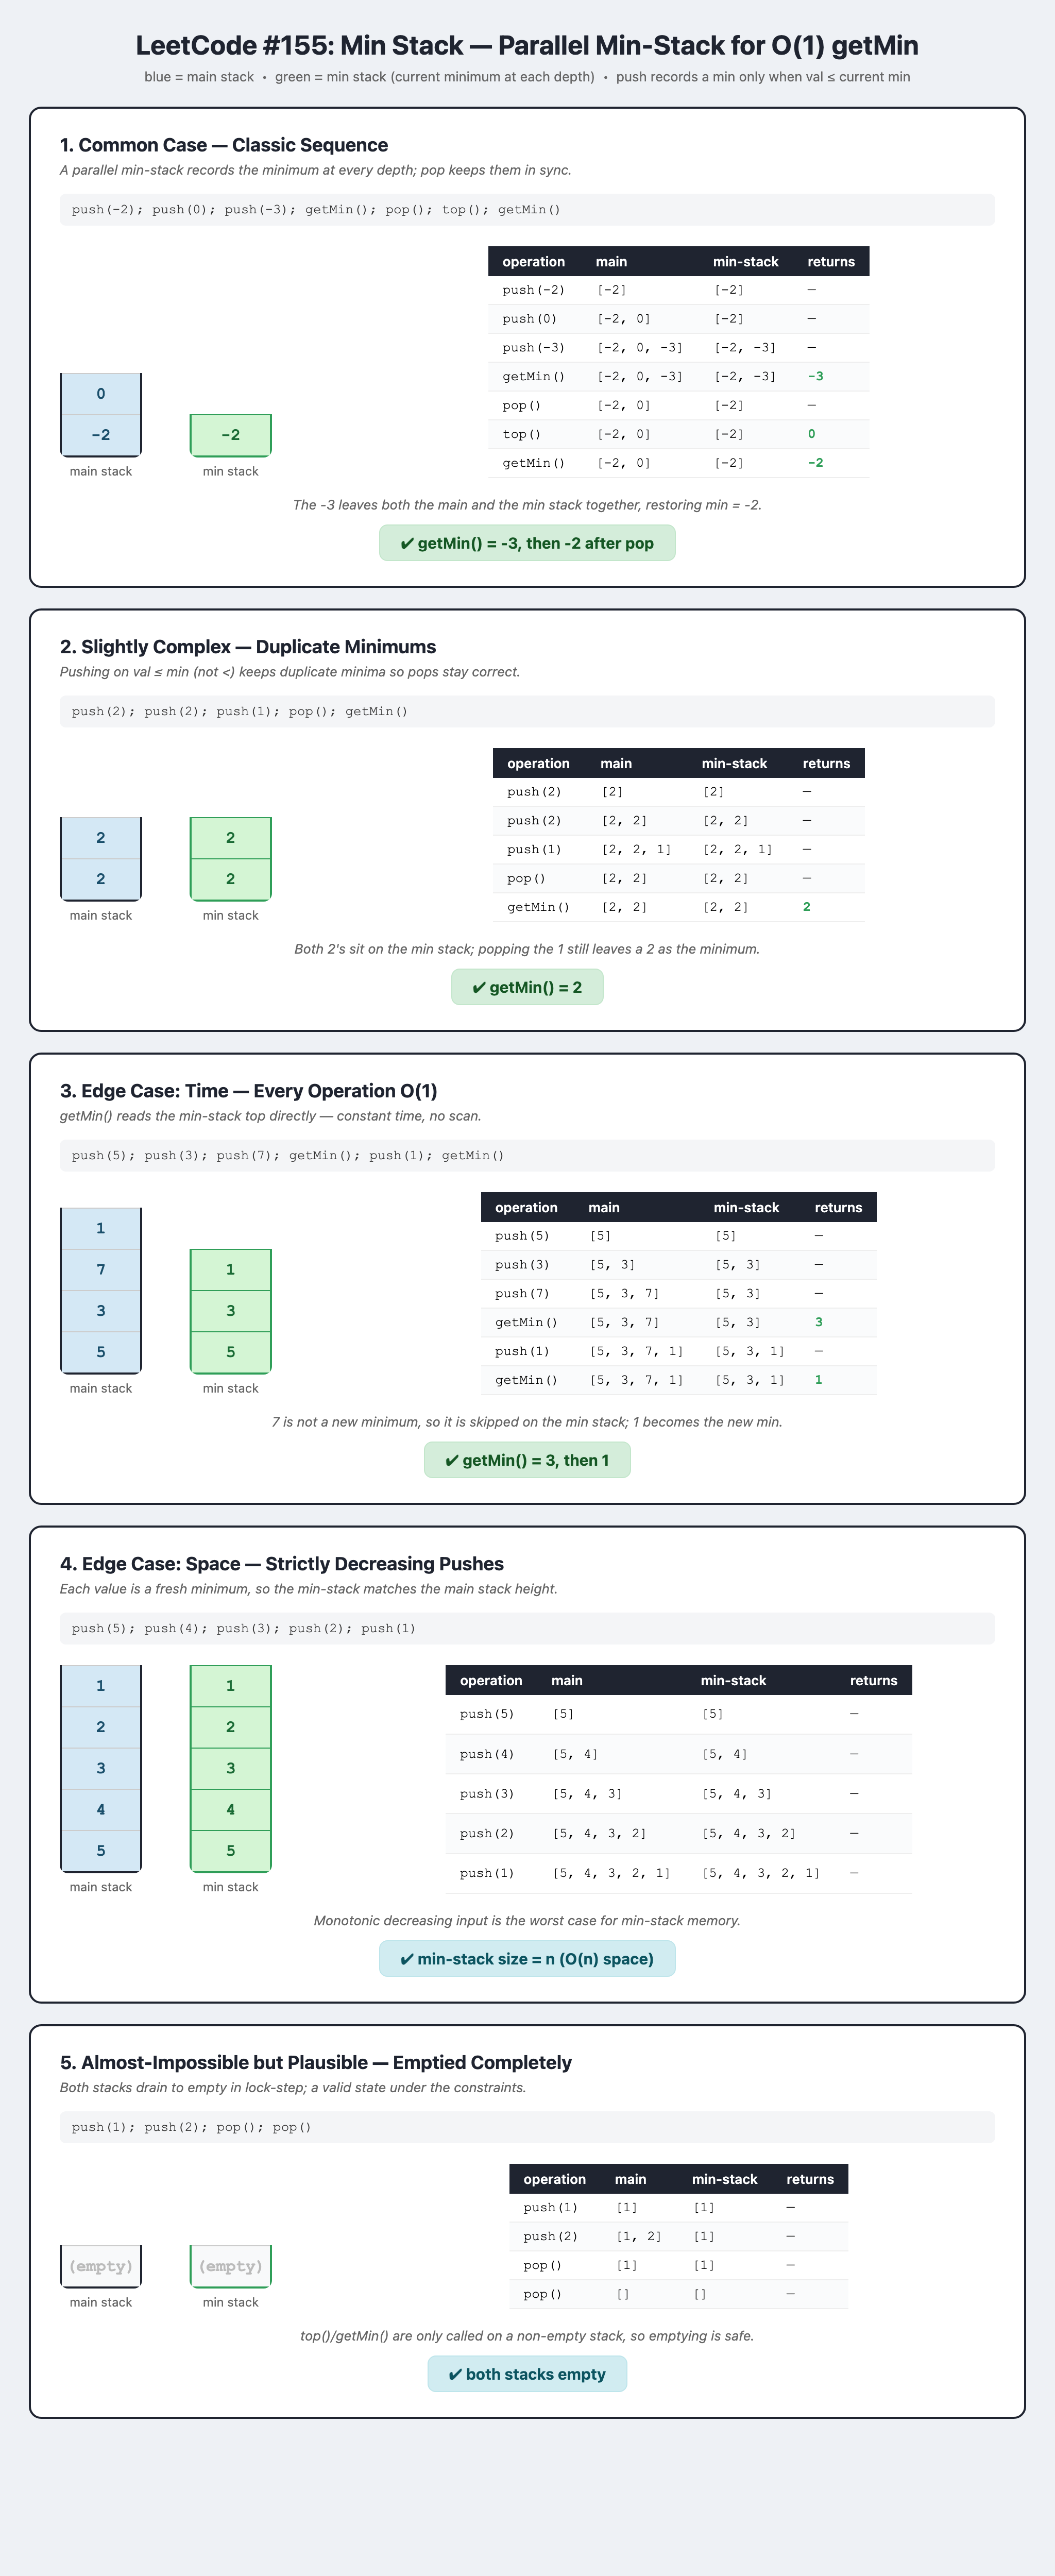